# Práctica 3. Análisis morfosintáctico del corpus

En esta práctica analizo la estructura gramatical del corpus de ofertas de empleo que construí en la
Práctica 1. La idea es pasar de contar palabras a ver qué tipo de palabras son: cuántos sustantivos,
verbos o adjetivos usa el corpus, cómo cambia eso a lo largo de un anuncio y si las ofertas
fraudulentas escriben distinto que las legítimas.

Uso las herramientas de NLTK que ya veníamos usando:

- **Etiquetado gramatical:** `pos_tag`, un etiquetador de perceptrón promediado entrenado con el
  corpus del Penn Treebank. Devuelve etiquetas finas (por ejemplo `NN`, `VBG`, `JJ`) que después
  agrupo en las 12 categorías del *universal tagset* para que sea más fácil leerlas.
- **Lematización:** `WordNetLemmatizer`, al que le paso la categoría gramatical de cada palabra,
  porque el lema depende de ella.

Parto de los archivos exportados en la Práctica 1, así que no repito la limpieza.

In [1]:
import gzip, json, re
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import nltk
from nltk import pos_tag_sents
from nltk.stem import WordNetLemmatizer
from nltk.tag import map_tag
from nltk.tokenize import word_tokenize

for recurso, ruta in [("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng"),
                      ("universal_tagset", "taggers/universal_tagset"),
                      ("wordnet", "corpora/wordnet.zip")]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

RUTA = Path("corpus_procesado")
if not RUTA.exists():
    RUTA = Path.home() / "Downloads" / "corpus_procesado"

documentos = []
with gzip.open(RUTA / "corpus_tokens.jsonl.gz", "rt", encoding="utf-8") as f:
    for linea in f:
        documentos.append(json.loads(linea))
metadatos = pd.read_csv(RUTA / "corpus_limpio.csv.gz", usecols=["doc_id", "industry"])
industrias = dict(zip(metadatos["doc_id"], metadatos["industry"]))

AZUL, NARANJA, VERDE, MORADO = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
GRIS, REJILLA = "#52514e", "#dcdcd8"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9.5,
                     "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.frameon": False, "legend.fontsize": 8.5})

def estilizar(ax, rejilla="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)

print(f"Documentos: {len(documentos):,}")
print(f"Oraciones:  {sum(len(d['oraciones']) for d in documentos):,}")

Documentos: 14,265
Oraciones:  471,700


## 1. Etiquetado gramatical (POS tagging)

El etiquetador trabaja oración por oración, porque necesita el contexto de las palabras vecinas y
las mayúsculas originales. Por eso no uso los tokens normalizados de la Práctica 1, que ya están en
minúsculas, sino las oraciones originales, que tokenizo de nuevo.

También descarto las oraciones con restos de estilos de Microsoft Word (`mso-...`), el ruido que
encontré en la Práctica 2. Etiquetar todo el corpus tarda unos dos minutos.

In [2]:
etiquetado = []        # por documento: lista de oraciones, cada una con sus pares (palabra, etiqueta)
descartadas = 0
for d in documentos:
    oraciones = []
    for oracion in d["oraciones"]:
        if "mso-" in oracion:
            descartadas += 1
            continue
        oraciones.append(word_tokenize(oracion))
    etiquetado.append(pos_tag_sents(oraciones))

# Traducción de las etiquetas finas del Penn Treebank a las categorías universales.
UNIVERSAL = {}
def universal(etiqueta):
    if etiqueta not in UNIVERSAL:
        UNIVERSAL[etiqueta] = map_tag("en-ptb", "universal", etiqueta)
    return UNIVERSAL[etiqueta]

NOMBRES = {"NOUN": "Sustantivo", "VERB": "Verbo", "ADJ": "Adjetivo", "ADV": "Adverbio",
           "PRON": "Pronombre", "ADP": "Preposición", "DET": "Determinante",
           "CONJ": "Conjunción", "PRT": "Partícula", "NUM": "Número", "X": "Otro"}

total_tokens = sum(len(o) for doc in etiquetado for o in doc)
print(f"Oraciones descartadas por estilos de Word: {descartadas:,}")
print(f"Tokens etiquetados: {total_tokens:,}")

Oraciones descartadas por estilos de Word: 1,615
Tokens etiquetados: 6,570,463


In [3]:
def buscar(inicio):
    for doc in etiquetado:
        for oracion in doc:
            if " ".join(w for w, _ in oracion).startswith(inicio):
                return oracion

ejemplos = ["We have a top editorial", "You will be responsible",
            "Excellent communication skills", "Apply now"]
for inicio in ejemplos:
    oracion = buscar(inicio)[:12]
    tabla = pd.DataFrame([[w for w, _ in oracion],
                          [t for _, t in oracion],
                          [universal(t) for _, t in oracion]],
                         index=["palabra", "Penn Treebank", "universal"])
    print(tabla.to_string(header=False), "\n")

palabra          We  have    a  top  editorial  ,  business  ,   and  engineering  team  .
Penn Treebank   PRP   VBP   DT   JJ         NN  ,        NN  ,    CC           NN    NN  .
universal      PRON  VERB  DET  ADJ       NOUN  .      NOUN  .  CONJ         NOUN  NOUN  . 

palabra         You  will    be  responsible  for  all  aspects   of  the  360  degree  Recruitment
Penn Treebank   PRP    MD    VB           JJ   IN   DT      NNS   IN   DT   CD      JJ          NNP
universal      PRON  VERB  VERB          ADJ  ADP  DET     NOUN  ADP  DET  NUM     ADJ         NOUN 

palabra        Excellent  communication  skills
Penn Treebank         JJ             NN     NNS
universal            ADJ           NOUN    NOUN 

palabra        Apply  now  with  your    CV   and  cover  letter  .
Penn Treebank     RB   RB    IN  PRP$   NNP    CC     RB      NN  .
universal        ADV  ADV   ADP  PRON  NOUN  CONJ    ADV    NOUN  . 



Los tres primeros ejemplos salen bien. En el primero se ve una oración normal con pronombre, verbo,
adjetivo y sustantivos. En el segundo aparece `will` como verbo modal (`MD`), que en este corpus es
muy común porque los anuncios hablan en futuro ("you will be..."). El tercero es una viñeta típica
de requisitos, sin ningún verbo.

El cuarto muestra un error del etiquetador: en "Apply now", `Apply` debería ser un verbo en
imperativo, pero sale como adverbio. Esto pasa porque el modelo se entrenó con texto periodístico,
donde las órdenes al lector son raras. En un anuncio de empleo son bastante comunes, así que es un
error que se va a repetir.

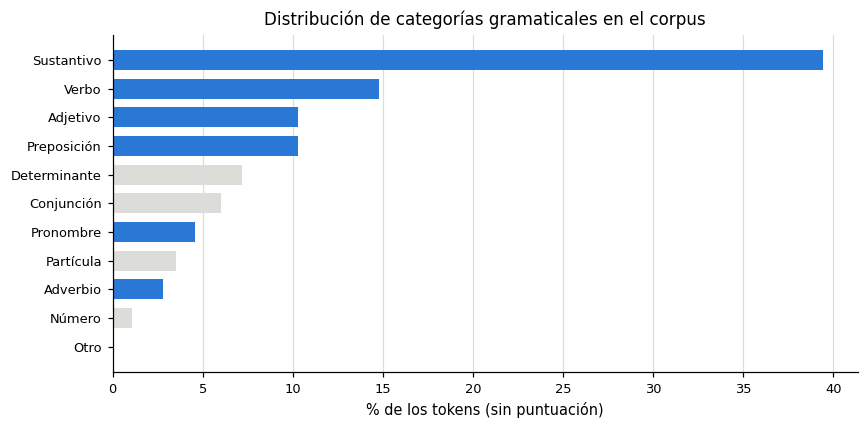

,nombre,categoria,tokens,%
0,Sustantivo,NOUN,2304307,39.4
1,Verbo,VERB,867627,14.8
2,Adjetivo,ADJ,600053,10.3
3,Preposición,ADP,599648,10.3
4,Determinante,DET,418810,7.2
5,Conjunción,CONJ,351497,6.0
6,Pronombre,PRON,268032,4.6
7,Partícula,PRT,202141,3.5
8,Adverbio,ADV,164280,2.8
9,Número,NUM,66916,1.1


In [4]:
conteo = Counter()
for doc in etiquetado:
    for oracion in doc:
        conteo.update(universal(t) for _, t in oracion)
del conteo["."]          # la puntuación no es una categoría gramatical

distribucion = pd.DataFrame(conteo.most_common(), columns=["categoria", "tokens"])
distribucion["nombre"] = distribucion["categoria"].map(NOMBRES)
distribucion["%"] = (100 * distribucion["tokens"] / distribucion["tokens"].sum()).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
pedidas = {"Sustantivo", "Verbo", "Adjetivo", "Adverbio", "Pronombre", "Preposición"}
colores = [AZUL if n in pedidas else REJILLA for n in distribucion["nombre"]]
ax.barh(distribucion["nombre"][::-1], distribucion["%"][::-1], color=colores[::-1], height=0.7)
ax.set_xlabel("% de los tokens (sin puntuación)")
ax.set_title("Distribución de categorías gramaticales en el corpus")
estilizar(ax, rejilla="x")
fig.tight_layout()
plt.show()

distribucion[["nombre", "categoria", "tokens", "%"]]

En azul marqué las seis categorías que pide el análisis; las grises son las demás.

Los sustantivos dominan con mucha diferencia: casi cuatro de cada diez palabras del corpus son
sustantivos, más del doble que los verbos. Después vienen los adjetivos y las preposiciones, más o
menos con el mismo peso, y muy por detrás los pronombres y los adverbios.

Tiene sentido para el tipo de texto. Un anuncio de empleo sobre todo enumera cosas: el puesto, las
habilidades, los requisitos, las prestaciones. Por eso abundan los sustantivos y los adjetivos que
los acompañan ("excellent communication skills", "competitive salary"), y se cuentan pocas acciones.
Los adverbios son raros porque casi no se describe cómo se hace algo, y los pronombres aparecen
sobre todo cuando la empresa habla de sí misma ("we", "our") o se dirige al candidato ("you").

Hay que tomar el porcentaje de sustantivos con un poco de cuidado. Revisando las etiquetas vi que el
modelo marca como nombre propio (`NNP`) muchas palabras comunes escritas con mayúscula inicial, como
`Manager`, `Knowledge` o incluso `Must`, porque los títulos y encabezados de los anuncios vienen así.
En las categorías universales esos casos siguen contando como sustantivos, así que el total es
correcto en lo general, pero las etiquetas finas de nombre propio están infladas.

## 2. Lematización

El lema es la forma de diccionario de una palabra: `skills` pasa a `skill` y `working` a `work`.
WordNet necesita saber la categoría gramatical, porque una misma forma puede tener lemas distintos:
`better` es `good` si es adjetivo y `well` si es adverbio. Por eso uso la etiqueta del paso anterior.
Solo lematizo sustantivos, verbos, adjetivos y adverbios; las demás palabras se quedan igual.

In [5]:
lematizador = WordNetLemmatizer()
WORDNET = {"NOUN": "n", "VERB": "v", "ADJ": "a", "ADV": "r"}
ya_calculados = {}       # guardo los lemas para no recalcular la misma palabra millones de veces

def lematizar(palabra, categoria):
    clave = (palabra, categoria)
    if clave not in ya_calculados:
        if categoria in WORDNET:
            ya_calculados[clave] = lematizador.lemmatize(palabra, WORDNET[categoria])
        else:
            ya_calculados[clave] = palabra
    return ya_calculados[clave]

ES_PALABRA = re.compile(r"^[a-z][a-z'\-]*$")
pares = Counter()        # (palabra, lema, categoría) -> frecuencia
for doc in etiquetado:
    for oracion in doc:
        for palabra, etiqueta in oracion:
            palabra = palabra.lower()
            if ES_PALABRA.match(palabra):
                cat = universal(etiqueta)
                pares[(palabra, lematizar(palabra, cat), cat)] += 1

formas = {p for p, _, _ in pares}
lemas = {l for _, l, _ in pares}
print(f"Palabras distintas antes de lematizar: {len(formas):,}")
print(f"Lemas distintos:                       {len(lemas):,}")
print(f"Reducción del vocabulario:             {1 - len(lemas) / len(formas):.1%}")

Palabras distintas antes de lematizar: 44,568
Lemas distintos:                       39,643
Reducción del vocabulario:             11.1%


In [6]:
casos = [("is", "VERB"), ("was", "VERB"), ("working", "VERB"), ("required", "VERB"),
         ("skills", "NOUN"), ("companies", "NOUN"), ("children", "NOUN"),
         ("better", "ADJ"), ("better", "ADV"),
         ("media", "NOUN"), ("sales", "NOUN"), ("sites", "VERB"), ("has", "NOUN")]
filas = []
for palabra, cat in casos:
    lema = lematizar(palabra, cat)
    filas.append((palabra, NOMBRES[cat], lema, pares[(palabra, lema, cat)]))
pd.DataFrame(filas, columns=["palabra original", "categoría", "lema", "frecuencia"])

,palabra original,categoría,lema,frecuencia
0,is,Verbo,be,55134
1,was,Verbo,be,1716
2,working,Verbo,work,12814
3,required,Verbo,require,7270
4,skills,Sustantivo,skill,19928
5,companies,Sustantivo,company,5600
6,children,Sustantivo,child,588
7,better,Adjetivo,good,1456
8,better,Adverbio,well,391
9,media,Sustantivo,medium,6480


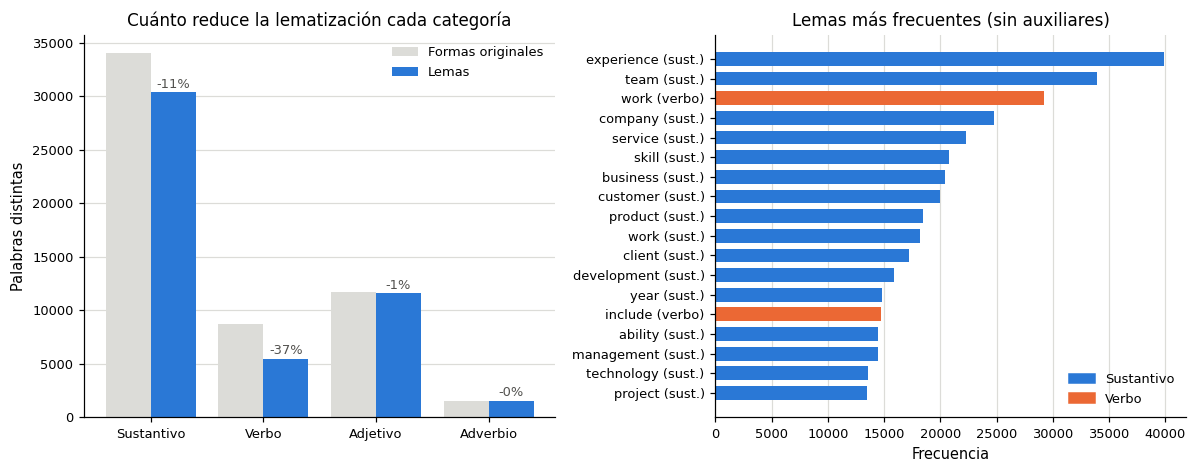

In [7]:
por_categoria = []
for cat in ["NOUN", "VERB", "ADJ", "ADV"]:
    f = {p for p, _, c in pares if c == cat}
    l = {lema for _, lema, c in pares if c == cat}
    por_categoria.append((NOMBRES[cat], len(f), len(l)))
por_categoria = pd.DataFrame(por_categoria, columns=["categoria", "formas", "lemas"])

frec_lemas = Counter()
AUXILIARES = {"be", "have", "will", "can", "do", "would", "should", "may", "must", "could"}
for (palabra, lema, cat), f in pares.items():
    if cat in ("NOUN", "VERB", "ADJ") and lema not in AUXILIARES:
        frec_lemas[(lema, cat)] += f

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))

x = np.arange(len(por_categoria))
ax1.bar(x - 0.2, por_categoria["formas"], 0.4, color=REJILLA, label="Formas originales")
ax1.bar(x + 0.2, por_categoria["lemas"], 0.4, color=AZUL, label="Lemas")
for i, fila in por_categoria.iterrows():
    reduccion = 1 - fila["lemas"] / fila["formas"]
    ax1.annotate(f"-{reduccion:.0%}", (i + 0.2, fila["lemas"]), xytext=(0, 3),
                 textcoords="offset points", ha="center", fontsize=8.5, color=GRIS)
ax1.set_xticks(x, por_categoria["categoria"])
ax1.set_ylabel("Palabras distintas")
ax1.set_title("Cuánto reduce la lematización cada categoría")
ax1.legend()
estilizar(ax1)

# Uso posiciones numéricas porque un mismo lema puede salir dos veces (work verbo y work sustantivo).
datos = frec_lemas.most_common(18)[::-1]
colores = {"NOUN": AZUL, "VERB": NARANJA, "ADJ": VERDE}
abreviatura = {"NOUN": "sust.", "VERB": "verbo", "ADJ": "adj."}
y = np.arange(len(datos))
ax2.barh(y, [f for _, f in datos], color=[colores[c] for (_, c), _ in datos], height=0.7)
ax2.set_yticks(y, [f"{lema} ({abreviatura[c]})" for (lema, c), _ in datos])
presentes = {c for (_, c), _ in datos}
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colores[c]) for c in colores if c in presentes],
           labels=[NOMBRES[c] for c in colores if c in presentes], loc="lower right")
ax2.set_xlabel("Frecuencia")
ax2.set_title("Lemas más frecuentes (sin auxiliares)")
estilizar(ax2, rejilla="x")
fig.tight_layout()
plt.show()

La lematización reduce el vocabulario mucho menos de lo que esperaba: alrededor de una décima parte.
Es por el idioma. El inglés casi no tiene flexión, así que la mayoría de las palabras ya están en su
forma base. La gráfica de la izquierda lo muestra por categoría: los verbos son los que más se
reducen, más de un tercio, porque tienen varias formas (`be` junta `is`, `are`, `was`, `were`,
`been`...). Los sustantivos solo pierden el plural, y los adjetivos y adverbios casi no cambian.

En la lista de lemas más frecuentes se ve que la lematización junta bien palabras que antes estaban
separadas, como `skills` y `skill`. También se ve que `work` aparece dos veces, como verbo y como
sustantivo. Como cada lema va con su categoría, "to work" y "the work" se cuentan aparte.

La tabla de ejemplos muestra también los problemas. Algunos lemas son correctos para el diccionario
pero cambian el sentido en este corpus: `media` pasa a `medium`, cuando aquí casi siempre aparece en
"social media", y `sales` pasa a `sale`, aunque en un anuncio "sales" es el área de ventas y no "una
venta". Otros errores vienen del etiquetado: cuando el modelo marca `sites` como verbo, WordNet le da
el lema `sit`, y cuando marca `has` como sustantivo, lo convierte en `ha`. O sea que la lematización
nunca es mejor que el etiquetado que recibe.

## 3. Análisis de categorías gramaticales

### 3.1 Etiquetas finas

Las categorías universales agrupan mucho. Las etiquetas del Penn Treebank dan más detalle, por
ejemplo el tiempo verbal o si un sustantivo está en plural.

In [8]:
finas = Counter()
for doc in etiquetado:
    for oracion in doc:
        finas.update(t for _, t in oracion)
total_finas = sum(finas.values())

DESCRIPCION = {
    "NN": "sustantivo singular", "NNS": "sustantivo plural", "NNP": "nombre propio",
    "JJ": "adjetivo", "VB": "verbo en forma base", "VBG": "verbo en gerundio (-ing)",
    "VBP": "verbo presente", "VBZ": "verbo presente 3a persona", "VBN": "participio",
    "VBD": "verbo pasado", "MD": "modal (will, can, must...)", "PRP": "pronombre personal",
    "PRP$": "pronombre posesivo", "RB": "adverbio", "IN": "preposición",
}
tabla_finas = pd.DataFrame([(t, DESCRIPCION[t], 100 * finas[t] / total_finas) for t in DESCRIPCION],
                           columns=["etiqueta", "significado", "%"]).round(2)

# Oraciones sin ningún verbo: casi siempre son viñetas.
sin_verbo = sum(1 for doc in etiquetado for o in doc if not any(universal(t) == "VERB" for _, t in o))
total_oraciones = sum(len(doc) for doc in etiquetado)
print(f"Oraciones sin ningún verbo: {sin_verbo:,} de {total_oraciones:,} ({sin_verbo / total_oraciones:.1%})\n")
tabla_finas.sort_values("%", ascending=False)

Oraciones sin ningún verbo: 148,649 de 470,085 (31.6%)



,etiqueta,significado,%
0,NN,sustantivo singular,17.56
14,IN,preposición,9.13
2,NNP,nombre propio,9.04
3,JJ,adjetivo,8.69
1,NNS,sustantivo plural,8.33
4,VB,verbo en forma base,3.83
5,VBG,verbo en gerundio (-ing),2.83
11,PRP,pronombre personal,2.38
6,VBP,verbo presente,2.21
13,RB,adverbio,2.17


Varias cosas salen de esta tabla. La primera es el tiempo verbal: el pasado (`VBD`) es casi
inexistente. Un anuncio no cuenta nada que ya pasó, habla de cómo es la empresa (presente) y de lo
que va a hacer el candidato (futuro). Por eso los modales, sobre todo `will`, aparecen bastante más
que el pasado.

La segunda es la cantidad de gerundios (`VBG`). En este corpus muchos describen tareas en forma de
lista: "managing accounts", "developing new features", "working closely with...". Es una manera de
enumerar responsabilidades sin armar oraciones completas.

La tercera, y la más clara, es que **casi un tercio de las oraciones no tiene ningún verbo**. Son las
viñetas del tipo "Excellent communication skills" o "Bachelor's degree in Computer Science". En la
Práctica 1 ya había notado que muchas oraciones eran muy cortas; el etiquetado confirma que no son
oraciones en sentido estricto, sino frases sustantivas sueltas.

### 3.2 Cambios a lo largo del documento

En la Práctica 2 vi que el vocabulario cambia según la parte del anuncio (presentación, requisitos,
prestaciones). Aquí reviso si también cambia la gramática. Parto cada documento en cinco tramos
según la posición de sus oraciones y calculo el porcentaje de cada categoría en cada tramo.

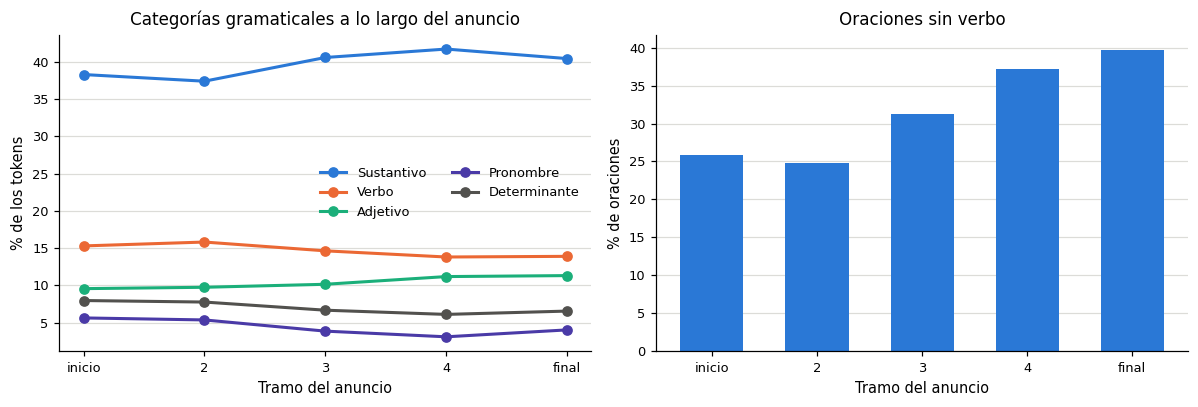

,Sustantivo,Verbo,Adjetivo,Pronombre,Determinante,Oraciones sin verbo
1,38.3,15.3,9.6,5.6,8.0,25.9
2,37.4,15.8,9.8,5.4,7.8,24.8
3,40.5,14.6,10.2,3.9,6.7,31.3
4,41.7,13.8,11.2,3.1,6.1,37.2
5,40.4,13.9,11.3,4.0,6.6,39.7


In [9]:
TRAMOS = 5
por_tramo = [Counter() for _ in range(TRAMOS)]
sin_verbo_tramo = [0] * TRAMOS
oraciones_tramo = [0] * TRAMOS

for doc in etiquetado:
    if len(doc) < TRAMOS:
        continue
    for i, oracion in enumerate(doc):
        tramo = min(int(TRAMOS * i / len(doc)), TRAMOS - 1)
        cats = [universal(t) for _, t in oracion]
        por_tramo[tramo].update(c for c in cats if c != ".")
        oraciones_tramo[tramo] += 1
        if "VERB" not in cats:
            sin_verbo_tramo[tramo] += 1

pct_tramo = pd.DataFrame([{NOMBRES[c]: 100 * cont[c] / sum(cont.values())
                           for c in ["NOUN", "VERB", "ADJ", "PRON", "DET"]}
                          for cont in por_tramo], index=range(1, TRAMOS + 1))
pct_tramo["Oraciones sin verbo"] = [100 * s / o for s, o in zip(sin_verbo_tramo, oraciones_tramo)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for nombre, color in [("Sustantivo", AZUL), ("Verbo", NARANJA), ("Adjetivo", VERDE),
                      ("Pronombre", MORADO), ("Determinante", GRIS)]:
    ax1.plot(pct_tramo.index, pct_tramo[nombre], "o-", color=color, linewidth=2, label=nombre)
ax1.set_xticks(range(1, TRAMOS + 1), ["inicio", "2", "3", "4", "final"])
ax1.set_xlabel("Tramo del anuncio")
ax1.set_ylabel("% de los tokens")
ax1.set_title("Categorías gramaticales a lo largo del anuncio")
ax1.legend(ncol=2)
estilizar(ax1)

ax2.bar(pct_tramo.index, pct_tramo["Oraciones sin verbo"], color=AZUL, width=0.6)
ax2.set_xticks(range(1, TRAMOS + 1), ["inicio", "2", "3", "4", "final"])
ax2.set_xlabel("Tramo del anuncio")
ax2.set_ylabel("% de oraciones")
ax2.set_title("Oraciones sin verbo")
estilizar(ax2)
fig.tight_layout()
plt.show()

pct_tramo.round(1)

La gramática también cambia de forma ordenada. Al inicio del anuncio hay más pronombres,
determinantes y verbos: es la parte donde la empresa se presenta con frases completas ("We are a
fast-growing company that..."). Conforme avanza el anuncio, los pronombres y determinantes bajan y
suben los sustantivos y adjetivos, porque llegan las listas de requisitos y prestaciones.

La gráfica de la derecha lo confirma: la proporción de oraciones sin verbo crece hacia el final. El
cierre del anuncio es casi una lista de cosas ("Competitive salary", "Health insurance", "Paid time
off"). Esto coincide con lo que vi en la Práctica 2 con el vocabulario, pero ahora desde la
gramática: el anuncio empieza como un texto narrativo y termina como un catálogo.

## 4. Comparación entre ofertas legítimas y fraudulentas

Las categorías que comparo son las del propio corpus: ofertas legítimas y fraudulentas. Para no dar
más peso a los anuncios largos, calculo los porcentajes en cada documento y después promedio por
categoría.

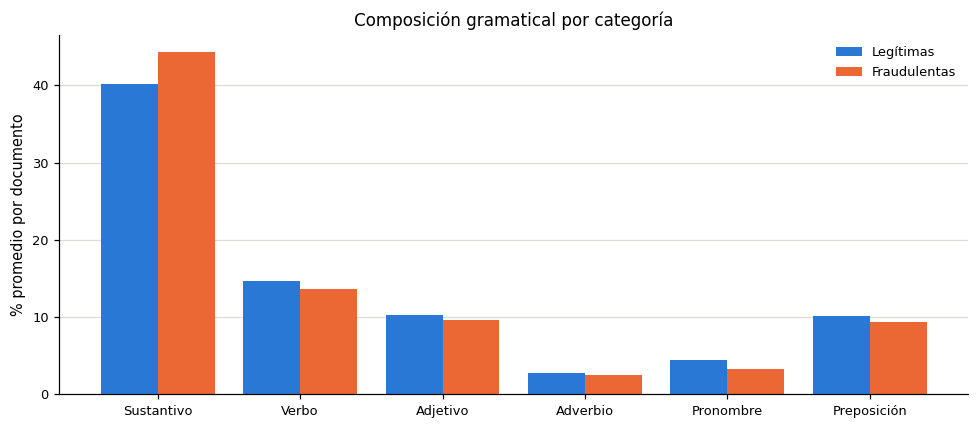

categoria,Fraudulenta,Legítima
sustantivos,0.438,0.395
verbos,0.131,0.148
pronombres,0.026,0.042
determinantes,0.060,0.071
números,0.012,0.009
oraciones sin verbo,0.366,0.294
palabras por oración,10.745,12.474


In [10]:
filas = []
for d, doc in zip(documentos, etiquetado):
    cont = Counter()
    pron = Counter()
    modales = Counter()
    sin_v = 0
    for oracion in doc:
        cats = [universal(t) for _, t in oracion]
        cont.update(c for c in cats if c != ".")
        if "VERB" not in cats:
            sin_v += 1
        for palabra, etiqueta in oracion:
            if etiqueta in ("PRP", "PRP$"):
                pron[palabra.lower()] += 1
            elif etiqueta == "MD":
                modales[palabra.lower()] += 1
    total = sum(cont.values())
    if total == 0:
        continue
    fila = {"doc_id": d["doc_id"], "categoria": d["categoria"],
            "industria": industrias[d["doc_id"]], "tokens": total,
            "sin_verbo": sin_v / max(len(doc), 1),
            "palabras_por_oracion": total / max(len(doc), 1)}
    fila.update({c: cont[c] / total for c in NOMBRES})
    fila.update({f"pron_{p}": pron[p] for p in ["we", "our", "you", "your", "they", "it"]})
    fila["pron_total"] = sum(pron.values())
    fila.update({f"md_{m}": modales[m] for m in ["will", "can", "must", "should", "may"]})
    fila["md_total"] = sum(modales.values())
    filas.append(fila)
por_doc = pd.DataFrame(filas)

pedidas = ["NOUN", "VERB", "ADJ", "ADV", "PRON", "ADP"]
medias = por_doc.groupby("categoria")[pedidas].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(pedidas))
ax.bar(x - 0.2, medias.loc["Legítima"], 0.4, color=AZUL, label="Legítimas")
ax.bar(x + 0.2, medias.loc["Fraudulenta"], 0.4, color=NARANJA, label="Fraudulentas")
ax.set_xticks(x, [NOMBRES[c] for c in pedidas])
ax.set_ylabel("% promedio por documento")
ax.set_title("Composición gramatical por categoría")
ax.legend()
estilizar(ax)
fig.tight_layout()
plt.show()

resumen = por_doc.groupby("categoria")[["NOUN", "VERB", "PRON", "DET", "NUM",
                                       "sin_verbo", "palabras_por_oracion"]].median()
resumen.columns = ["sustantivos", "verbos", "pronombres", "determinantes", "números",
                   "oraciones sin verbo", "palabras por oración"]
resumen.T.round(3)

Las ofertas fraudulentas tienen un estilo más telegráfico. Usan más sustantivos y menos verbos,
pronombres y determinantes, tienen más oraciones sin verbo y sus oraciones son un poco más cortas.
La mediana por documento dice lo mismo que el promedio, así que no es efecto de unos pocos anuncios
raros.

Esto encaja con lo que encontré en la Práctica 1: dos de cada tres ofertas fraudulentas no tienen
perfil de empresa. El perfil es justo la parte más narrativa del anuncio, donde aparecen los "we",
"our" y las frases completas. Si falta, lo que queda es sobre todo la lista de requisitos, y por eso
la gramática se ve más sustantiva. Es decir, al menos una parte de esta diferencia podría venir de
lo que el anuncio omite, más que de una forma distinta de escribir.

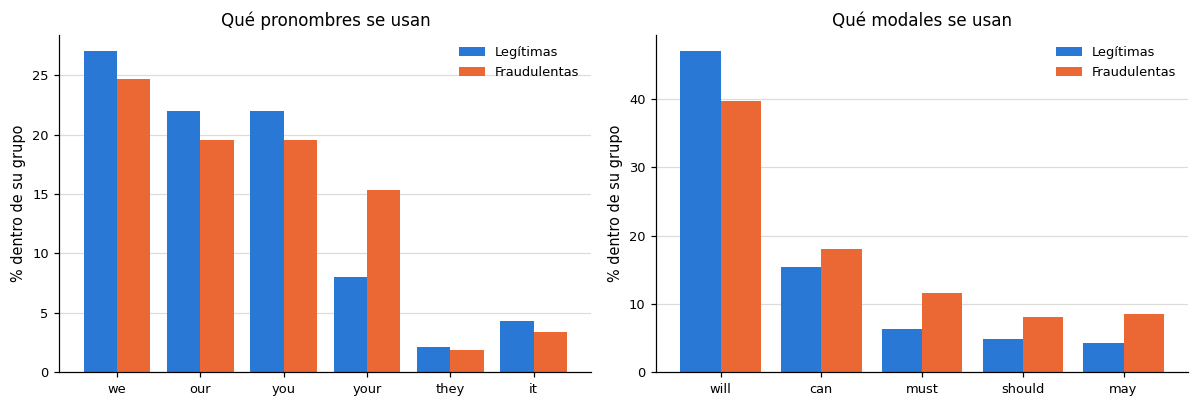

In [11]:
def proporciones(prefijo, palabras, total):
    suma = por_doc.groupby("categoria")[[f"{prefijo}_{p}" for p in palabras] + [total]].sum()
    return pd.DataFrame({p: 100 * suma[f"{prefijo}_{p}"] / suma[total] for p in palabras})

pronombres = proporciones("pron", ["we", "our", "you", "your", "they", "it"], "pron_total")
modales = proporciones("md", ["will", "can", "must", "should", "may"], "md_total")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tabla, titulo in [(ax1, pronombres, "Qué pronombres se usan"),
                          (ax2, modales, "Qué modales se usan")]:
    x = np.arange(tabla.shape[1])
    ax.bar(x - 0.2, tabla.loc["Legítima"], 0.4, color=AZUL, label="Legítimas")
    ax.bar(x + 0.2, tabla.loc["Fraudulenta"], 0.4, color=NARANJA, label="Fraudulentas")
    ax.set_xticks(x, tabla.columns)
    ax.set_ylabel("% dentro de su grupo")
    ax.set_title(titulo)
    ax.legend()
    estilizar(ax)
fig.tight_layout()
plt.show()

Aquí aparece una diferencia que no tiene que ver con la cantidad de texto, sino con a quién le
habla el anuncio. Entre los pronombres que usan, las ofertas fraudulentas recurren mucho más a
`your`: "your CV", "your skills", "your application". Le hablan directamente al candidato y ponen
lo que este va a ganar o tiene que mandar en el centro del mensaje. Las legítimas reparten más el
peso entre `we`, `our` y `you`.

En los modales, las legítimas usan bastante más `will`, es decir, describen lo que el candidato va
a hacer en el puesto. Las fraudulentas usan un poco más `must`, `should` y `may`. Antes de darle
importancia a esto conviene revisar si se sostiene al comparar dentro de una misma industria, que
hago al final de esta sección.

In [12]:
verbos = defaultdict(Counter)
adjetivos = defaultdict(Counter)
for d, doc in zip(documentos, etiquetado):
    for oracion in doc:
        for palabra, etiqueta in oracion:
            palabra = palabra.lower()
            if not ES_PALABRA.match(palabra):
                continue
            cat = universal(etiqueta)
            lema = lematizar(palabra, cat)
            if cat == "VERB" and etiqueta != "MD" and lema not in AUXILIARES:
                verbos[d["categoria"]][lema] += 1
            elif cat == "ADJ":
                adjetivos[d["categoria"]][lema] += 1

comparacion = pd.DataFrame({
    "verbos legítimas": [v for v, _ in verbos["Legítima"].most_common(15)],
    "verbos fraudulentas": [v for v, _ in verbos["Fraudulenta"].most_common(15)],
    "adjetivos legítimas": [a for a, _ in adjetivos["Legítima"].most_common(15)],
    "adjetivos fraudulentas": [a for a, _ in adjetivos["Fraudulenta"].most_common(15)],
}, index=range(1, 16))
comparacion

,verbos legítimas,verbos fraudulentas,adjetivos legítimas,adjetivos fraudulentas
1,work,work,new,other
2,include,include,strong,new
3,provide,require,other,high
4,look,provide,high,strong
5,make,look,great,technical
6,help,develop,good,more
7,require,offer,more,good
8,use,need,excellent,able
9,grow,make,best,professional
10,build,use,technical,global


Los primeros verbos son casi los mismos en las dos categorías (`work`, `include`, `provide`,
`require`, `look`). Son los verbos del género: cualquier anuncio dice qué se ofrece, qué se requiere
y a quién se busca. Las diferencias están más abajo en la lista. Las legítimas tienen verbos de
crecimiento y creación (`grow`, `build`, `create`, `help`) que no entran en la lista de las
fraudulentas. En estas, `offer` y `need` suben varios puestos y aparecen `maintain` y `manage`, que
son verbos de mantener y administrar más que de construir algo nuevo.

En los adjetivos el contraste es todavía más claro. Las legítimas usan adjetivos valorativos y
entusiastas como `great`, `best` o `creative`, junto con `social` y `digital`, que vienen de las
empresas tecnológicas. Ninguno de ellos está en la lista de las fraudulentas, que en su lugar tienen
adjetivos más formales y de oficina: `competitive`, `administrative`, `corporate`, `global` y
`responsible`. Es el mismo contraste que vi en la Práctica 2 con palabras como `awesome` o `excited`,
que casi no aparecen en los anuncios falsos.

### 4.1 Comparación dentro de la misma industria

En la Práctica 1 descubrí que muchas ofertas fraudulentas pertenecen al sector petrolero. Si cada
industria escribe de forma distinta, parte de lo que vi arriba podría ser el sector y no el fraude.
Para revisarlo, repito la comparación solo dentro de las cuatro industrias con más ofertas
fraudulentas.

In [13]:
principales = por_doc[por_doc["categoria"] == "Fraudulenta"]["industria"].value_counts().head(4).index
filas = []
for industria in principales:
    grupo = por_doc[por_doc["industria"] == industria]
    for cat, g in grupo.groupby("categoria"):
        filas.append({
            "industria": industria, "categoria": cat, "documentos": len(g),
            "sustantivos %": 100 * g["NOUN"].median(),
            "pronombres %": 100 * g["PRON"].median(),
            "oraciones sin verbo %": 100 * g["sin_verbo"].median(),
            "'your' entre pronombres %": 100 * g["pron_your"].sum() / g["pron_total"].sum(),
            "'will' entre modales %": 100 * g["md_will"].sum() / g["md_total"].sum(),
            "'must' entre modales %": 100 * g["md_must"].sum() / g["md_total"].sum(),
        })
pd.DataFrame(filas).set_index(["industria", "categoria"]).round(1)

documentos  sustantivos %  \
industria                 categoria                                
Oil & Energy              Fraudulenta         107           44.2   
                          Legítima            130           42.8   
Accounting                Fraudulenta          46           45.5   
                          Legítima             72           39.9   
Hospital & Health Care    Fraudulenta          43           44.1   
                          Legítima            374           43.3   
Marketing and Advertising Fraudulenta          36           41.1   
                          Legítima            660           38.2   

                                       pronombres %  oraciones sin verbo %  \
industria                 categoria                                          
Oil & Energy              Fraudulenta           2.5                   37.5   
                          Legítima              2.0                   35.8   
Accounting                Fraudulenta           1.2                   34.6   
                          Legítima              4.5                   31.1   
Hospital & Health Care    Fraudulenta           2.0                   37.5   
                          Legítima              3.0                   37.9   
Marketing and Advertising Fraudulenta           3.9                   34.3   
                          Legítima              4.9                   30.3   

                                       'your' entre pronombres %  \
industria                 categoria                                
Oil & Energy              Fraudulenta                       20.5   
                          Legítima                          17.4   
Accounting                Fraudulenta                       15.8   
                          Legítima                           9.4   
Hospital & Health Care    Fraudulenta                       13.7   
                          Legítima                           7.9   
Marketing and Advertising Fraudulenta                       13.9   
                          Legítima                           8.3   

                                       'will' entre modales %  \
industria                 categoria                             
Oil & Energy              Fraudulenta                    40.3   
                          Legítima                       61.6   
Accounting                Fraudulenta                    55.2   
                          Legítima                       57.2   
Hospital & Health Care    Fraudulenta                    35.7   
                          Legítima                       55.5   
Marketing and Advertising Fraudulenta                    36.0   
                          Legítima                       48.5   

                                       'must' entre modales %  
industria                 categoria                            
Oil & Energy              Fraudulenta                     4.7  
                          Legítima                        5.7  
Accounting                Fraudulenta                    19.0  
                          Legítima                        5.2  
Hospital & Health Care    Fraudulenta                    16.3  
                          Legítima                        8.2  
Marketing and Advertising Fraudulenta                     4.5  
                          Legítima                        6.3

Esta tabla matiza bastante las conclusiones anteriores. En *Oil & Energy*, la industria con más
fraudes, las diferencias de composición gramatical casi desaparecen: legítimas y fraudulentas tienen
proporciones parecidas de sustantivos, pronombres y oraciones sin verbo. En *Hospital & Health Care*
la diferencia también es pequeña. Solo en *Accounting* y en *Marketing and Advertising* se mantiene
con claridad el estilo más sustantivo de las fraudulentas. Por lo tanto, buena parte de la diferencia
gramatical que vi en general se explica por el sector y no por el fraude.

Lo que sí se mantiene en las cuatro industrias es el uso de `your`: en todas, los anuncios
fraudulentos lo usan más. El menor uso de `will` también se repite en casi todas. En cambio, el
`must` solo sube en dos de las cuatro, así que no lo tomaría como un rasgo del fraude.

Hay que tener en cuenta que dentro de cada industria hay pocos anuncios fraudulentos, entre algunas
decenas y un centenar, así que estas cifras se mueven fácilmente. Aun así, el patrón de `your` es el
rasgo gramatical más consistente que encontré: el anuncio falso habla más directamente al lector.

Por último guardo el corpus etiquetado y las proporciones por documento, para usarlos en las
prácticas de sintaxis y semántica sin volver a etiquetar.

In [14]:
with gzip.open(RUTA / "corpus_pos.jsonl.gz", "wt", encoding="utf-8") as f:
    for d, doc in zip(documentos, etiquetado):
        f.write(json.dumps({
            "doc_id": d["doc_id"],
            "categoria": d["categoria"],
            "tokens": [[w for w, _ in o] for o in doc],
            "pos": [[t for _, t in o] for o in doc],
            "lemas": [[lematizar(w.lower(), universal(t)) for w, t in o] for o in doc],
        }, ensure_ascii=False) + "\n")

por_doc.to_csv(RUTA / "pos_por_documento.csv", index=False)

for nombre in ["corpus_pos.jsonl.gz", "pos_por_documento.csv"]:
    print(f"{nombre:<24} {(RUTA / nombre).stat().st_size / 1024**2:6.1f} MB")

corpus_pos.jsonl.gz        26.5 MB
pos_por_documento.csv       4.1 MB
